# Лабораторна робота №1. Побудова простої трансформерної моделі
## Частина 4: Побудова, навчання, оптимізація та оцінювання мовної моделі на основі Transformer Decoder

**Дисципліна:** «Нейромережеві технології і системи»  
**Тема:** «Побудова простої трансформерної моделі»  
**Варіант завдання 2:** Авторегресивна генерація тексту за допомогою Transformer Decoder  
**Корпус:** `WikiText-2` (підготовлені віконні тензори з `data/processed/wikitext_processed.pt`)

---

### Теоретичні засади архітектури Transformer Decoder

На відміну від двонаправленого енкодера, **Transformer Decoder** моделює текст **авторегресивно** (зліва направо), прогнозуючи кожен наступний токен $w_{t}$ за передісторією $w_{<t}$.

#### 1. Причинна маска уваги (Causal Masking)
Для запобігання використанню інформації про майбутні токени скалярний добуток уваги модифікується адитивною верхньотрикутною маскою $M_{\text{causal}}$:
$$\text{CausalAttention}(Q, K, V) = \text{softmax}\left(\frac{QK^T}{\sqrt{d_k}} + M_{\text{causal}}\right) V$$
де елементи маски визначено як:
$$M_{\text{causal}}(i, j) = \begin{cases} 0, & j \le i \\ -\infty, & j > i \end{cases}$$
Для будь-якої позиції майбутнього $j > i$ додавання $-\infty$ перед експонентою функції Softmax забезпечує нульовий коефіцієнт уваги:
$$\exp\left(\frac{QK^T_{i, j}}{\sqrt{d_k}} + (-\infty)\right) = 0 \implies \alpha_{i, j} = 0 \quad (\forall j > i)$$
Для попередніх та поточної позицій ($j \le i$) коефіцієнти Softmax нормалізуються лише за доступним лівим контекстом:
$$\alpha_{i, j} = \frac{\exp\left(\frac{QK^T_{i, j}}{\sqrt{d_k}}\right)}{\sum_{m=1}^i \exp\left(\frac{QK^T_{i, m}}{\sqrt{d_k}}\right)}$$

#### 2. Адаптація PyTorch TransformerDecoderLayer для Decoder-Only LM
Шар `nn.TransformerDecoderLayer` у PyTorch спочатку спроєктований для seq2seq-моделей і містить два блоки уваги:
1. *Causal Self-Attention* (причинна увага до послідовності `tgt`).
2. *Cross-Attention* (увага до виходів енкодера `memory`).
У задачі авторегресивного мовного моделювання без зовнішнього енкодера тензор `memory` задається сталим нульовим вектором форми $[B, 1, d_{\text{model}}]$. Це дає змогу використати наявний бібліотечний шар PyTorch без створення нового модуля, хоча операції Cross-Attention продовжують формально виконуватися над фіксованим нульовим вектором (на відміну від канонічних decoder-only моделей на кшталт GPT, де блок Cross-Attention відсутній повністю).

#### 3. Перплексія (Perplexity, PPL)
Функція втрат моделі обчислюється як середня крос-ентропія за всіма передбаченими токенами:
$$\mathcal{L}_{\text{LM}} = -\frac{1}{N} \sum_{t=1}^N \log P(w_t \mid w_{<t})$$
**Перплексія (Perplexity)** визначається як експонента функції втрат:
$$\text{PPL} = \exp(\mathcal{L}_{\text{LM}}) = \exp\left(-\frac{1}{N} \sum_{t=1}^N \log P(w_t \mid w_{<t})\right)$$
Інформаційно перплексія відображає ефективний коефіцієнт розгалуження (branching factor) або міру невизначеності моделі. Наприклад, значення $\text{PPL} = 148.48$ відповідає невизначеності рівномірного розподілу над приблизно 148 токенами (для порівняння, рівномірний випадковий вибір над словником $|\mathcal{V}|=10\,000$ дав би теоретичне значення $\text{PPL} = 10\,000$).

#### 4. Стратегії декодування
* **Жадібне декодування (Greedy Decoding):** на кожному кроці обирається токен із найвищою умовною ймовірністю $w_t = \arg\max_{w \in \mathcal{V}} P(w \mid w_{<t})$. У компактних моделях це часто призводить до зациклення на частих уніграмах і біграмах.
* **Стохастичне семплювання (Temperature, Top-$k$, Repetition Penalty):** масштабування логітів температурою $T$, обмеження вибору $k$ найімовірнішими токенами та штрафування повторів розривають циклічні петлі й урізноманітнюють текст.

In [1]:
import sys
import math
import json
import time
from pathlib import Path

# Динамічне визначення кореня проєкту (підтримує як робочий каталог notebooks/, так і корінь проєкту)
current_dir = Path.cwd().resolve()
if (current_dir / "utils.py").exists():
    LAB_ROOT = current_dir
elif (current_dir / ".." / "utils.py").resolve().exists():
    LAB_ROOT = (current_dir / "..").resolve()
else:
    LAB_ROOT = next((p for p in [current_dir, *current_dir.parents] if (p / "utils.py").exists()), current_dir)
if str(LAB_ROOT) not in sys.path:
    sys.path.insert(0, str(LAB_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
from rouge_score import rouge_scorer

from utils import (
    PAD_IDX, UNK_IDX, BOS_IDX, EOS_IDX,
    PAD_TOKEN, UNK_TOKEN, BOS_TOKEN, EOS_TOKEN,
    Vocabulary, tokenize_text, create_causal_mask,
    PositionalEncoding, set_seed, setup_plot_style,
    generate_text_autoregressive
)

set_seed(42)
setup_plot_style()

DATA_DIR = LAB_ROOT / "data"
PROCESSED_DATA_DIR = DATA_DIR / "processed"
OUTPUTS_DIR = LAB_ROOT / "outputs"
CHECKPOINTS_DIR = OUTPUTS_DIR / "checkpoints"
METRICS_DIR = OUTPUTS_DIR / "metrics"
FIGURES_DIR = OUTPUTS_DIR / "figures"

for d in [CHECKPOINTS_DIR, METRICS_DIR, FIGURES_DIR]:
    d.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
hw_info = pd.DataFrame([{
    "Пристрій": str(device).upper(),
    "GPU": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU",
    "Доступна VRAM": f"{torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB" if torch.cuda.is_available() else "N/A",
    "PyTorch": torch.__version__
}])
print("Апаратне середовище для декодера:")
display(hw_info)

Апаратне середовище для декодера:


,Пристрій,GPU,Доступна VRAM,PyTorch
0,CUDA,NVIDIA GeForce RTX 3050 Laptop GPU,4.00 GB,2.14.0+cu130


---
## 1. Завантаження даних WikiText-2 та DataLoader

Завантажуємо підготовлений файл `data/processed/wikitext_processed.pt` і створюємо генератори пакетів `DataLoader` із розміром батчу $B = 32$.

In [2]:
data_path = PROCESSED_DATA_DIR / "wikitext_processed.pt"
assert data_path.exists(), f"Файл {data_path} не знайдено! Спочатку запустіть Ноутбук №3."

payload = torch.load(data_path, map_location="cpu", weights_only=False)

train_inputs = payload["train_inputs"]
train_targets = payload["train_targets"]
val_inputs = payload["val_inputs"]
val_targets = payload["val_targets"]
test_inputs = payload["test_inputs"]
test_targets = payload["test_targets"]
vocab = Vocabulary.from_dict(payload["vocab"])
config = payload["config"]

BATCH_SIZE = 64

train_loader = DataLoader(TensorDataset(train_inputs, train_targets), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TensorDataset(val_inputs, val_targets), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(TensorDataset(test_inputs, test_targets), batch_size=BATCH_SIZE, shuffle=False)

data_summary = pd.DataFrame([
    {
        "Підмножина": "Train",
        "Вікон (послідовностей)": len(train_inputs),
        "Батчів": len(train_loader),
        "Розмір батчу": BATCH_SIZE,
        "Цільових токенів": train_targets.numel(),
        "Тензор входу": str(list(train_inputs.shape)),
        "Тензор цілей": str(list(train_targets.shape))
    },
    {
        "Підмножина": "Validation",
        "Вікон (послідовностей)": len(val_inputs),
        "Батчів": len(val_loader),
        "Розмір батчу": BATCH_SIZE,
        "Цільових токенів": val_targets.numel(),
        "Тензор входу": str(list(val_inputs.shape)),
        "Тензор цілей": str(list(val_targets.shape))
    },
    {
        "Підмножина": "Test",
        "Вікон (послідовностей)": len(test_inputs),
        "Батчів": len(test_loader),
        "Розмір батчу": BATCH_SIZE,
        "Цільових токенів": test_targets.numel(),
        "Тензор входу": str(list(test_inputs.shape)),
        "Тензор цілей": str(list(test_targets.shape))
    }
])
print("Параметри навчальних та тестових генераторів пакетів (DataLoaders):")
display(data_summary)

Параметри навчальних та тестових генераторів пакетів (DataLoaders):


,Підмножина,Вікон (послідовностей),Батчів,Розмір батчу,Цільових токенів,Тензор входу,Тензор цілей
0,Train,33529,524,64,2145856,"[33529, 64]","[33529, 64]"
1,Validation,3501,55,64,224064,"[3501, 64]","[3501, 64]"
2,Test,3946,62,64,252544,"[3946, 64]","[3946, 64]"


---
## 2. Причинна маска уваги (Causal Mask) та експериментальна верифікація

Візуалізуємо нижньотрикутну булеву маску уваги для послідовності довжини 16 та проводимо експериментальний тест на відсутність витоку інформації з майбутнього: порівнюємо виходи моделі для двох послідовностей з однаковими першими токенами і різними наступними.

findfont: Failed to find font weight semibold for Arial, now using 700.


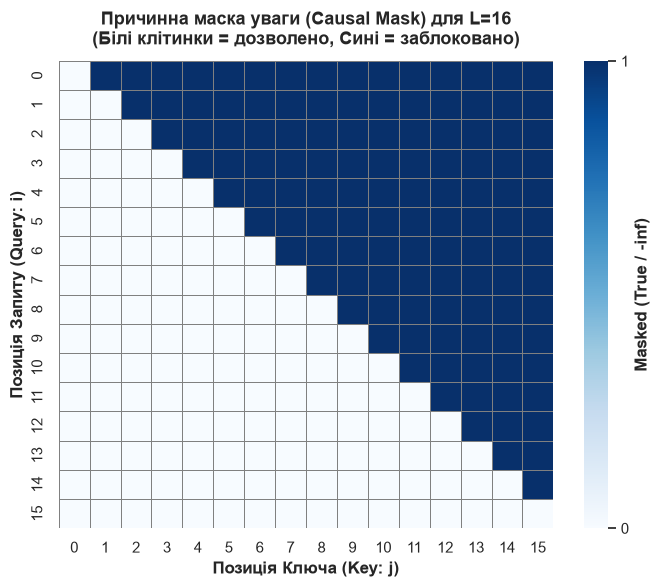

Результати експериментального тесту на відсутність витоку даних:


,Критерій верифікації,Фактичний результат,Статус
0,Виходи на позиціях 0..3 ідентичні,True,PASS (Витоку немає)
1,Виходи на позиціях 4..7 різняться,True,PASS (Майбутнє впливає на майбутнє)


In [3]:
mask_16 = create_causal_mask(16).numpy()

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(
    mask_16, cmap="Blues", cbar=True, ax=ax,
    linewidths=0.5, linecolor="gray",
    cbar_kws={"ticks": [0, 1], "label": "Masked (True / -inf)"}
)
ax.set_title("Причинна маска уваги (Causal Mask) для L=16\n(Білі клітинки = дозволено, Сині = заблоковано)", pad=12)
ax.set_xlabel("Позиція Ключа (Key: j)")
ax.set_ylabel("Позиція Запиту (Query: i)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "wikitext_causal_mask.png")
plt.show()

# 2. Експериментальний тест на витік інформації
test_emb = nn.Embedding(len(vocab), 32)
test_layer = nn.TransformerDecoderLayer(d_model=32, nhead=2, dim_feedforward=64, batch_first=True)
test_dec = nn.TransformerDecoder(test_layer, num_layers=1)
test_dec.eval()

# Два батчі з однаковим початком, але різними майбутніми токенами
s1 = torch.tensor([[10, 20, 30, 40, 50, 60, 70, 80]])
s2 = torch.tensor([[10, 20, 30, 40, 99, 98, 97, 96]])

with torch.no_grad():
    c_m = create_causal_mask(8)
    mem = torch.zeros(1, 1, 32)
    o1 = test_dec(test_emb(s1), mem, tgt_mask=c_m)
    o2 = test_dec(test_emb(s2), mem, tgt_mask=c_m)

leak_test_passed = torch.allclose(o1[:, :4, :], o2[:, :4, :], atol=1e-5)
future_diff_passed = not torch.allclose(o1[:, 4:, :], o2[:, 4:, :], atol=1e-4)

leak_summary_df = pd.DataFrame([
    {
        "Критерій верифікації": "Виходи на позиціях 0..3 ідентичні",
        "Фактичний результат": leak_test_passed,
        "Статус": "PASS (Витоку немає)" if leak_test_passed else "FAIL"
    },
    {
        "Критерій верифікації": "Виходи на позиціях 4..7 різняться",
        "Фактичний результат": future_diff_passed,
        "Статус": "PASS (Майбутнє впливає на майбутнє)" if future_diff_passed else "FAIL"
    }
])
print("Результати експериментального тесту на відсутність витоку даних:")
display(leak_summary_df)

---
## 3. Архітектура Transformer Decoder Language Model

Клас `TransformerDecoderLM` містить:
1. `nn.Embedding(vocab_size, d_model)` із масштабуванням $\sqrt{d_{\text{model}}}$.
2. `PositionalEncoding(d_model, max_len=64)`.
3. `nn.TransformerDecoder` з нульовою `memory` та причинною маскою `tgt_mask`.
4. `nn.Linear(d_model, vocab_size)` для проектування вихідних векторів у логіти словника.

In [4]:
class TransformerDecoderLM(nn.Module):
    def __init__(
        self,
        vocab_size: int,
        d_model: int = 64,
        nhead: int = 2,
        dim_feedforward: int = 256,
        num_layers: int = 1,
        max_seq_len: int = 64,
        dropout: float = 0.1
    ):
        super().__init__()
        self.d_model = d_model
        self.vocab_size = vocab_size
        self.embedding = nn.Embedding(vocab_size, d_model, padding_idx=PAD_IDX)
        self.pos_encoder = PositionalEncoding(d_model=d_model, max_len=max_seq_len, dropout=dropout)
        
        decoder_layer = nn.TransformerDecoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True
        )
        self.decoder = nn.TransformerDecoder(decoder_layer, num_layers=num_layers)
        self.projection = nn.Linear(d_model, vocab_size)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        batch_size, seq_len = x.shape
        device = x.device
        
        c_mask = create_causal_mask(seq_len, device=device)
        pad_mask = (x == PAD_IDX)
        
        emb = self.embedding(x) * math.sqrt(self.d_model)
        emb = self.pos_encoder(emb)
        
        # Стала нульова пам'ять (Decoder-Only LM)
        memory = emb.new_zeros(batch_size, 1, self.d_model)
        
        decoded = self.decoder(
            tgt=emb,
            memory=memory,
            tgt_mask=c_mask,
            tgt_key_padding_mask=pad_mask
        )
        logits = self.projection(decoded)
        return logits

demo_decoder = TransformerDecoderLM(vocab_size=len(vocab), d_model=128, nhead=4).to(device)
dummy_in = train_inputs[:2].to(device)
dummy_logits = demo_decoder(dummy_in)

decoder_params = []
for name, p in demo_decoder.named_parameters():
    decoder_params.append({
        "Модуль": name,
        "Розмірність": str(list(p.shape)),
        "Параметрів": p.numel()
    })
dec_param_df = pd.DataFrame(decoder_params)

print(f"Розмірність вихідних логітів мовної моделі: {dummy_logits.shape} [B, L, |V|]")
print(f"Загальна кількість параметрів моделі (128d, 4h, 1 layer): {dec_param_df['Параметрів'].sum():,}")
display(dec_param_df.head(8))

Розмірність вихідних логітів мовної моделі: torch.Size([2, 64, 10000]) [B, L, |V|]
Загальна кількість параметрів моделі (128d, 4h, 1 layer): 2,768,784


,Модуль,Розмірність,Параметрів
0,embedding.weight,"[10000, 128]",1280000
1,decoder.layers.0.self_attn.in_proj_weight,"[384, 128]",49152
2,decoder.layers.0.self_attn.in_proj_bias,[384],384
3,decoder.layers.0.self_attn.out_proj.weight,"[128, 128]",16384
4,decoder.layers.0.self_attn.out_proj.bias,[128],128
5,decoder.layers.0.multihead_attn.in_proj_weight,"[384, 128]",49152
6,decoder.layers.0.multihead_attn.in_proj_bias,[384],384
7,decoder.layers.0.multihead_attn.out_proj.weight,"[128, 128]",16384


---
## 4. Навчальний цикл та обчислення перплексії (Perplexity)

Навчальний крок розгортає логіти у форму $[B \cdot L, |\mathcal{V}|]$ і обчислює крос-ентропію з ігноруванням токенів `<pad>`. Перплексія розраховується як $\text{PPL} = \exp(\text{Loss})$. Для запобігання переповнення експоненти на перших ітераціях значення втрат обмежується значенням $\le 20$.

In [5]:
def train_lm_epoch(model, loader, criterion, optimizer, dev):
    model.train()
    total_loss = 0.0
    total_tokens = 0
    for inputs, targets in loader:
        inputs, targets = inputs.to(dev), targets.to(dev)
        optimizer.zero_grad()
        logits = model(inputs)
        loss = criterion(logits.view(-1, model.vocab_size), targets.view(-1))
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        
        non_pad_tokens = (targets != PAD_IDX).sum().item()
        total_loss += loss.item() * non_pad_tokens
        total_tokens += non_pad_tokens
        
    return total_loss / total_tokens if total_tokens > 0 else 0.0

def evaluate_lm_ppl(model, loader, criterion, dev):
    model.eval()
    total_loss = 0.0
    total_tokens = 0
    with torch.no_grad():
        for inputs, targets in loader:
            inputs, targets = inputs.to(dev), targets.to(dev)
            logits = model(inputs)
            loss = criterion(logits.view(-1, model.vocab_size), targets.view(-1))
            non_pad_tokens = (targets != PAD_IDX).sum().item()
            total_loss += loss.item() * non_pad_tokens
            total_tokens += non_pad_tokens
            
    avg_loss = total_loss / total_tokens if total_tokens > 0 else 0.0
    ppl = math.exp(min(avg_loss, 20.0))
    return avg_loss, ppl

---
## 5. Тюнінг гіперпараметрів декодера (`d_model` та `nhead`)

Досліджуються конфігурації $d_{\text{model}} \in \{64, 128\}$ та $n_{\text{head}} \in \{2, 4\}$. Критерій оптимізації — мінімальна валідаційна перплексія (Validation PPL).

У контрольованому режимі (`FORCE_RETRAIN = False`) завантажуються збережені результати сіткового пошуку.

[Контрольований режим]: Завантажено збережені результати тюнінгу гіперпараметрів (FORCE_RETRAIN=False)...
Зведена таблиця порівняння конфігурацій декодера:


,Config,d_model,nhead,num_layers,Parameters,Time (s),Val Loss,Val Perplexity
0,d64_h2,64,2,1,1356752,24.5,5.2996,200.26
1,d64_h4,64,4,1,1356752,25.1,5.2967,199.67
2,d128_h2,128,2,1,2768784,33.0,5.1949,180.35
3,d128_h4,128,4,1,2768784,34.2,5.1926,179.93



Обрано найкращу конфігурацію: d128_h4 (Validation PPL = 179.93)


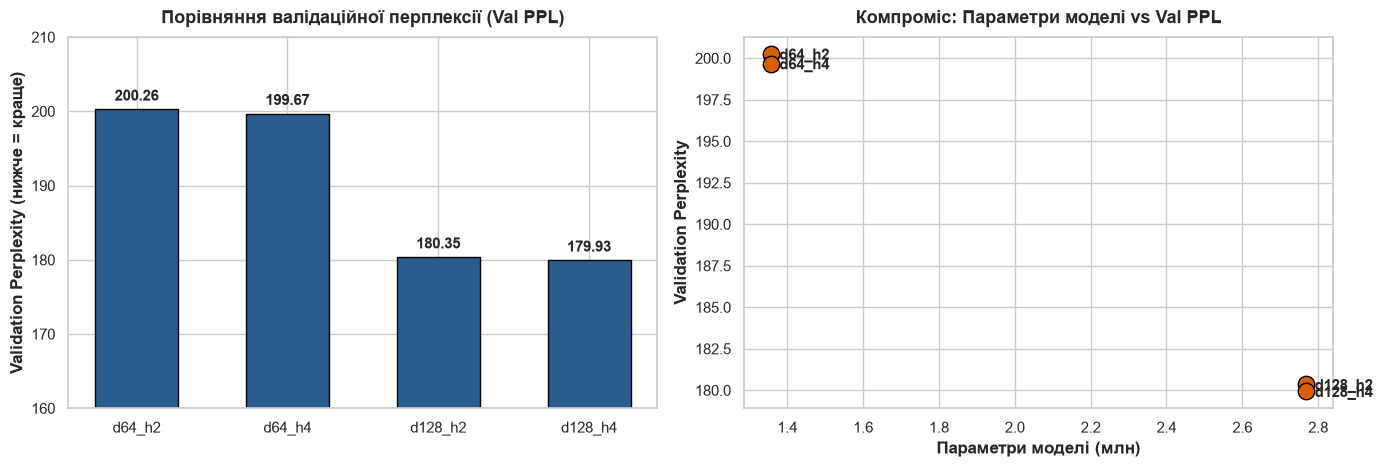

In [6]:
decoder_tuning_configs = [
    {"d_model": 64, "nhead": 2, "num_layers": 1, "dim_ff": 256},
    {"d_model": 64, "nhead": 4, "num_layers": 1, "dim_ff": 256},
    {"d_model": 128, "nhead": 2, "num_layers": 1, "dim_ff": 256},
    {"d_model": 128, "nhead": 4, "num_layers": 1, "dim_ff": 256},
]

FORCE_RETRAIN = False
tuning_results_file = METRICS_DIR / "wikitext_tuning_results.csv"

if tuning_results_file.exists() and not FORCE_RETRAIN:
    print("[Контрольований режим]: Завантажено збережені результати тюнінгу гіперпараметрів (FORCE_RETRAIN=False)...")
    tuning_df = pd.read_csv(tuning_results_file)
else:
    tuning_results = []
    TUNING_EPOCHS = 1
    criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)

    for i, cfg in enumerate(decoder_tuning_configs, 1):
        print(f"\n[Експеримент {i}/{len(decoder_tuning_configs)}] Decoder: d_model={cfg['d_model']}, nhead={cfg['nhead']}...")
        set_seed(42)
        model = TransformerDecoderLM(
            vocab_size=len(vocab),
            d_model=cfg["d_model"],
            nhead=cfg["nhead"],
            dim_feedforward=cfg["dim_ff"],
            num_layers=cfg["num_layers"]
        ).to(device)
        
        optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
        param_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
        
        start_time = time.time()
        for epoch in range(1, TUNING_EPOCHS + 1):
            tr_loss = train_lm_epoch(model, train_loader, criterion, optimizer, device)
            val_loss, val_ppl = evaluate_lm_ppl(model, val_loader, criterion, device)
            
        elapsed = time.time() - start_time
        tuning_results.append({
            "Config": f"d{cfg['d_model']}_h{cfg['nhead']}",
            "d_model": cfg["d_model"],
            "nhead": cfg["nhead"],
            "num_layers": cfg["num_layers"],
            "Parameters": param_count,
            "Time (s)": round(elapsed, 1),
            "Val Loss": round(val_loss, 4),
            "Val Perplexity": round(val_ppl, 2),
        })

    tuning_df = pd.DataFrame(tuning_results)
    tuning_df.to_csv(tuning_results_file, index=False)

print("Зведена таблиця порівняння конфігурацій декодера:")
display(tuning_df)

ppl_col = "Val Perplexity" if "Val Perplexity" in tuning_df.columns else "Val PPL"
best_idx = tuning_df[ppl_col].idxmin()
best_cfg = decoder_tuning_configs[best_idx]
print(f"\nОбрано найкращу конфігурацію: {tuning_df.loc[best_idx, 'Config']} (Validation PPL = {tuning_df.loc[best_idx, ppl_col]:.2f})")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

bars = axes[0].bar(tuning_df["Config"], tuning_df[ppl_col], color="#2b5c8f", edgecolor="black", width=0.55)
axes[0].set_title("Порівняння валідаційної перплексії (Val PPL)", pad=10)
axes[0].set_ylabel("Validation Perplexity (нижче = краще)")
axes[0].set_ylim(160, 210)
for bar in bars:
    yval = bar.get_height()
    axes[0].annotate(f"{yval:.2f}",
                     xy=(bar.get_x() + bar.get_width() / 2, yval),
                     xytext=(0, 4), textcoords="offset points",
                     ha="center", va="bottom", fontweight="bold")

axes[1].scatter(tuning_df["Parameters"] / 1e6, tuning_df[ppl_col], color="#d95f02", s=140, edgecolors="black", zorder=3)
for i, row in tuning_df.iterrows():
    axes[1].annotate(row["Config"], xy=(row["Parameters"] / 1e6, row[ppl_col]),
                     xytext=(6, -4), textcoords="offset points", fontweight="bold")
axes[1].set_title("Компроміс: Параметри моделі vs Val PPL", pad=10)
axes[1].set_xlabel("Параметри моделі (млн)")
axes[1].set_ylabel("Validation Perplexity")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "wikitext_tuning_comparison.png")
plt.show()

---
## 6. Фінальне навчання найкращої конфігурації декодера (`d128_h4`)

Конфігурацію ($d_{\text{model}}=128$, $n_{\text{head}}=4$, $d_{\text{ff}}=256$) навчаємо протягом 6 епох з оптимізатором AdamW ($lr=10^{-3}$, weight decay $=10^{-4}$). Чекпоінт із найнижчою валідаційною перплексією зберігається у `outputs/checkpoints/best_wikitext_decoder.pt`.

In [7]:
set_seed(42)

final_decoder = TransformerDecoderLM(
    vocab_size=len(vocab),
    d_model=best_cfg["d_model"],
    nhead=best_cfg["nhead"],
    dim_feedforward=best_cfg["dim_ff"],
    num_layers=best_cfg["num_layers"],
    dropout=0.1
).to(device)

optimizer = torch.optim.AdamW(final_decoder.parameters(), lr=1e-3, weight_decay=1e-4)
criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)

NUM_EPOCHS = 6
best_val_ppl = float("inf")
best_checkpoint_path = CHECKPOINTS_DIR / "best_wikitext_decoder.pt"
history_file = METRICS_DIR / "wikitext_training_history.csv"

if best_checkpoint_path.exists() and history_file.exists() and not FORCE_RETRAIN:
    print(f"[Контрольований режим]: Знайдено натренований чекпоінт: {best_checkpoint_path.name}")
    ckpt = torch.load(best_checkpoint_path, weights_only=False, map_location=device)
    final_decoder.load_state_dict(ckpt["model_state_dict"])
    hw_df = pd.read_csv(history_file)
    history_wiki = hw_df.to_dict(orient="list")
    print(f"Відновлено чекпоінт: епоха {ckpt['epoch']}, найкращий Val PPL = {ckpt['best_val_ppl']:.2f}")
else:
    history_wiki = {"epoch": [], "train_loss": [], "val_loss": [], "val_ppl": []}

    print(f"Початок фінального навчання Transformer Decoder ({best_cfg['d_model']}d, {best_cfg['nhead']}h)...")
    for epoch in range(1, NUM_EPOCHS + 1):
        tr_loss = train_lm_epoch(final_decoder, train_loader, criterion, optimizer, device)
        val_loss, val_ppl = evaluate_lm_ppl(final_decoder, val_loader, criterion, device)
        
        history_wiki["epoch"].append(epoch)
        history_wiki["train_loss"].append(tr_loss)
        history_wiki["val_loss"].append(val_loss)
        history_wiki["val_ppl"].append(val_ppl)
        
        if val_ppl < best_val_ppl:
            best_val_ppl = val_ppl
            torch.save({
                "model_state_dict": final_decoder.state_dict(),
                "config": best_cfg,
                "vocab": vocab.to_dict(),
                "best_val_ppl": best_val_ppl,
                "epoch": epoch
            }, best_checkpoint_path)

    pd.DataFrame(history_wiki).to_csv(history_file, index=False)

print("\nЗведена історія фінального навчання декодера:")
display(pd.DataFrame(history_wiki))

[Контрольований режим]: Знайдено натренований чекпоінт: best_wikitext_decoder.pt
Відновлено чекпоінт: епоха 6, найкращий Val PPL = 159.00

Зведена історія фінального навчання декодера:


,epoch,train_loss,val_loss,val_ppl
0,1,5.8387,5.3413,208.78
1,2,5.3418,5.1926,179.93
2,3,5.1942,5.1485,172.18
3,4,5.1113,5.1045,164.77
4,5,5.0496,5.0843,161.47
5,6,5.0044,5.0689,159.00


---
## 7. Візуалізація кривих динаміки навчання мовної моделі

Криві динаміки втрат (Loss) та перплексії (PPL) на навчальній і валідаційній вибірках відображають темп збіжності оптимізації протягом 6 епох.

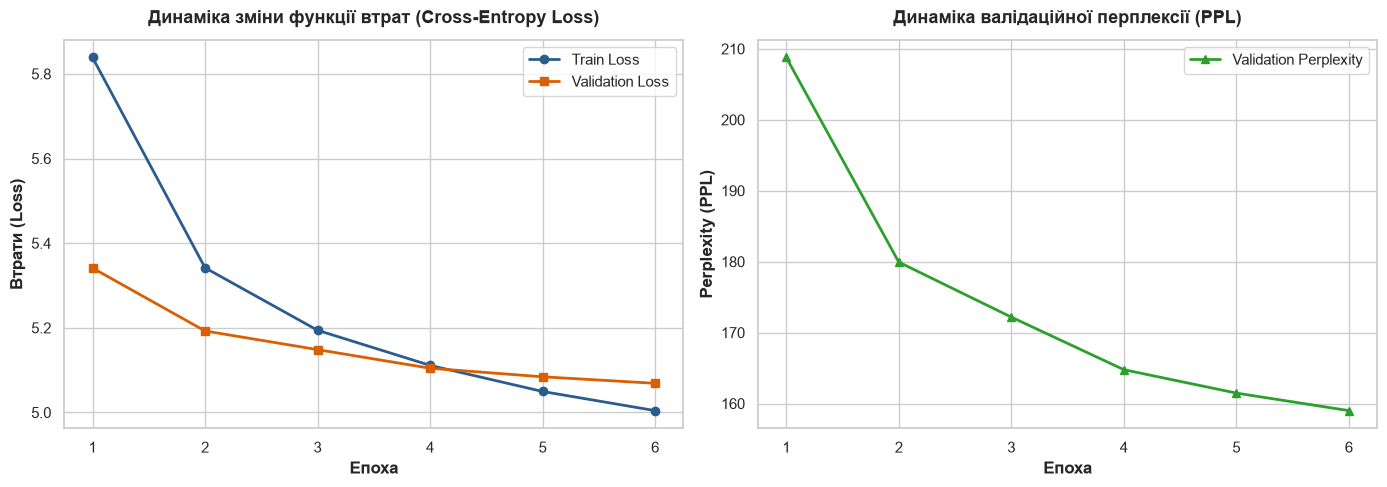

In [8]:
hw_df = pd.DataFrame(history_wiki)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(hw_df["epoch"], hw_df["train_loss"], label="Train Loss", marker="o", color="#2b5c8f", lw=2)
axes[0].plot(hw_df["epoch"], hw_df["val_loss"], label="Validation Loss", marker="s", color="#d95f02", lw=2)
axes[0].set_title("Динаміка зміни функції втрат (Cross-Entropy Loss)", pad=12)
axes[0].set_xlabel("Епоха")
axes[0].set_ylabel("Втрати (Loss)")
axes[0].legend()

axes[1].plot(hw_df["epoch"], hw_df["val_ppl"], label="Validation Perplexity", marker="^", color="#2ca02c", lw=2)
axes[1].set_title("Динаміка валідаційної перплексії (PPL)", pad=12)
axes[1].set_xlabel("Епоха")
axes[1].set_ylabel("Perplexity (PPL)")
axes[1].legend()

plt.tight_layout()
plt.savefig(FIGURES_DIR / "wikitext_training_loss.png")
plt.show()

---
## 8. Авторегресивна генерація тексту: Жадібний пошук проти Стохастичного семплювання

Жадібне декодування детерміністично обирає токен із найвищою **умовною ймовірністю**:
$$w_t = \arg\max_{w \in \mathcal{V}} P(w \mid w_{<t})$$
У компактних мовних моделях це призводить до зациклення на частих уніграмах і біграмах (`", and , and"`).

Для регулювання стохастичності застосовуються три параметри семплювання:
1. **Temperature ($T = 0.85$):** масштабування логітів $z_i / T$. Значення $T < 1.0$ збільшує відносний розрив між логітами і робить розподіл Softmax більш концентрованим навколо найімовірніших слів (на відміну від $T > 1.0$, який розгладжує розподіл у бік рівномірного).
2. **Top-$k$ ($k = 25$):** відсікання малоймовірних слів із залишенням лише 25 найімовірніших кандидатів перед ренормалізацією.
3. **Repetition Penalty ($1.25$):** зменшення логітів токенів, які вже з'являлися у згенерованому контексті.

Порівняння стратегій авторегресивної генерації тексту:


,Вхідний промпт,1) Greedy Decoding (Argmax),"2) Top-k Sampling (T=0.85, k=25)"
0,valkyria chronicles iii is a,", and , and , and , and , and",second . @ - in which contains his wife of the...
1,the game was released in,"the , and , and , and , and ,",". the of his own , and a group were also called"
2,tower was designed by architect,", and , and , and , and , and",", and to the song ' t really . it is in the first"
3,in the second half of the,", and , and , and , and , and","world for best video game "" and that it was de..."
4,he was educated at trinity college,football league football league football leagu...,", and his son of by the two days . they were a..."


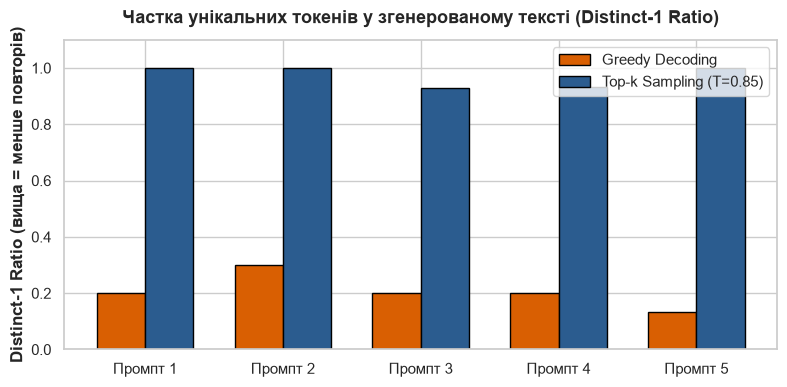

In [9]:
test_prompts = [
    "valkyria chronicles iii is a",
    "the game was released in",
    "tower was designed by architect",
    "in the second half of the",
    "he was educated at trinity college"
]

generation_comparison = []
for p in test_prompts:
    greedy_res, _ = generate_text_autoregressive(
        p, final_decoder, vocab, device, max_new_tokens=15, do_sample=False
    )
    sample_res, _ = generate_text_autoregressive(
        p, final_decoder, vocab, device, max_new_tokens=15, do_sample=True,
        temperature=0.85, top_k=25, repetition_penalty=1.25
    )
    generation_comparison.append({
        "Вхідний промпт": p,
        "1) Greedy Decoding (Argmax)": greedy_res,
        "2) Top-k Sampling (T=0.85, k=25)": sample_res
    })

gen_df = pd.DataFrame(generation_comparison)
print("Порівняння стратегій авторегресивної генерації тексту:")
display(gen_df)

# Аналіз розмаїття токенів (Distinct Tokens Ratio)
def compute_distinct_ratio(text):
    toks = tokenize_text(text)
    return len(set(toks)) / len(toks) if toks else 0.0

greedy_ratios = [compute_distinct_ratio(r["1) Greedy Decoding (Argmax)"]) for r in generation_comparison]
sample_ratios = [compute_distinct_ratio(r["2) Top-k Sampling (T=0.85, k=25)"]) for r in generation_comparison]

fig, ax = plt.subplots(figsize=(8, 4))
x_idx = np.arange(len(test_prompts))
w = 0.35

ax.bar(x_idx - w/2, greedy_ratios, width=w, label="Greedy Decoding", color="#d95f02", edgecolor="black")
ax.bar(x_idx + w/2, sample_ratios, width=w, label="Top-k Sampling (T=0.85)", color="#2b5c8f", edgecolor="black")
ax.set_xticks(x_idx)
ax.set_xticklabels([f"Промпт {i+1}" for i in range(len(test_prompts))])
ax.set_title("Частка унікальних токенів у згенерованому тексті (Distinct-1 Ratio)", pad=12)
ax.set_ylabel("Distinct-1 Ratio (вища = менше повторів)")
ax.set_ylim(0, 1.1)
ax.legend()

plt.tight_layout()
plt.savefig(FIGURES_DIR / "wikitext_diversity_comparison.png")
plt.show()

---
## 9. Фінальне кількісне оцінювання мовної моделі на Test Split

Оцінювання якості мовної моделі на незалежній тестовій вибірці:
1. **Перплексія (Perplexity):** розраховується на всіх 252 544 цільових токенах тестового спліту.
2. **Метрики збігу (BLEU та ROUGE-L):** обчислюються на 50 випадкових тестових підказках довжиною 15 токенів шляхом порівняння згенерованого продовження з авторським текстом.

Фінальні кількісні метрики мовного моделювання на Test Split:


,Test Perplexity,Test Loss,Mean BLEU (n=50),Mean ROUGE-L (n=50),Всього тестових токенів
0,148.48,5.0004,0.0226,0.0493,252544



Приклади перших 5 тестових пар (Prompt -> Generated vs Reference):


,Prompt,Reference,Generated (Greedy),BLEU,ROUGE-L
0,"= robert = robert is an english film , televi...",actor . he had a guest @ - @ starring role on...,", and , and , and , and , and...",0.0000,0.0000
1,a guest role in the television series judge j...,"landed a role as "" craig "" in the episode "" '...",", and , and , and , and , and...",0.0000,0.0000
2,"fur , which was performed at the drum theatre...",factory in london . he was directed by john a...,", and , and , and , and , and...",0.0156,0.1176
3,appeared on a 2006 episode of the television ...,role in the 2007 theatre production of how to...,", and , and , and , and , and...",0.0000,0.0000
4,"directed by blackburn . in may 2008 , made a ...",on a two @ - @ part episode arc of the televi...,"of the , and , and , and , and...",0.0299,0.2353


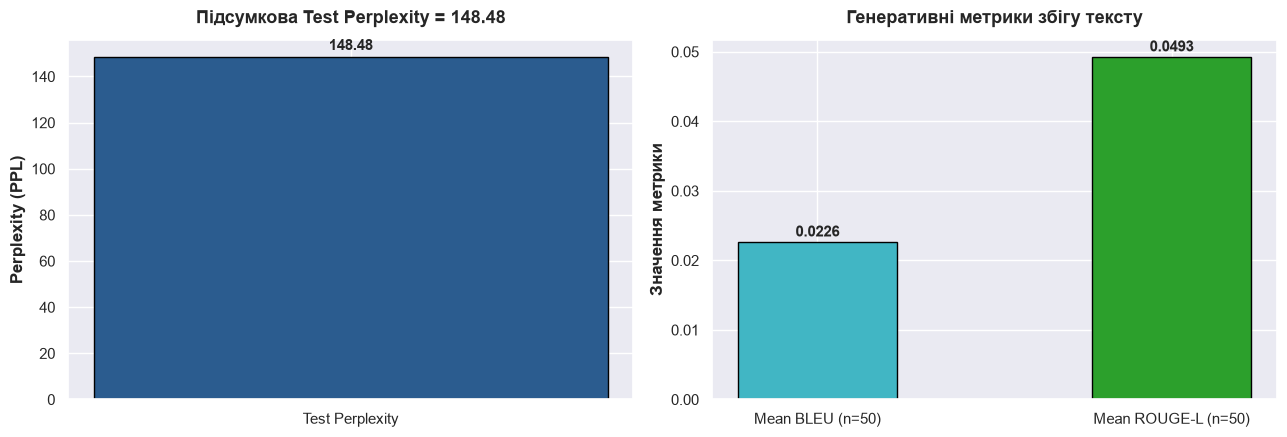

In [11]:
# 1. Фінальна перплексія на Test Split
test_loss, test_ppl = evaluate_lm_ppl(final_decoder, test_loader, criterion, device)

# 2. Оцінка BLEU та ROUGE-L на 50 підказках
smooth_fn = SmoothingFunction().method1
rouge_evaluator = rouge_scorer.RougeScorer(["rougeL"], use_stemmer=True)

NUM_EVAL_SAMPLES = 50
PROMPT_LEN = 15
GEN_LEN = 15

bleu_scores = []
rouge_scores = []
eval_records = []

for idx in range(NUM_EVAL_SAMPLES):
    sample_window = test_inputs[idx].tolist()
    prompt_ids = sample_window[:PROMPT_LEN]
    ref_ids = sample_window[PROMPT_LEN : PROMPT_LEN + GEN_LEN]
    
    prompt_str = vocab.decode(prompt_ids)
    ref_str = vocab.decode(ref_ids)
    
    gen_continuation_str, _ = generate_text_autoregressive(
        prompt_str, final_decoder, vocab, device, max_new_tokens=GEN_LEN, do_sample=False
    )
    
    ref_tokens = tokenize_text(ref_str)
    gen_tokens = tokenize_text(gen_continuation_str)
    
    b_score = sentence_bleu([ref_tokens], gen_tokens, smoothing_function=smooth_fn)
    bleu_scores.append(b_score)
    
    r_score = rouge_evaluator.score(ref_str, gen_continuation_str)["rougeL"].fmeasure
    rouge_scores.append(r_score)
    
    if idx < 5:
        eval_records.append({
            "Prompt": prompt_str[:45] + "...",
            "Reference": ref_str[:45] + "...",
            "Generated (Greedy)": gen_continuation_str[:45] + "...",
            "BLEU": round(b_score, 4),
            "ROUGE-L": round(r_score, 4)
        })

mean_bleu = float(np.mean(bleu_scores))
mean_rouge = float(np.mean(rouge_scores))

final_gen_metrics = {
    "Test Perplexity": round(test_ppl, 2),
    "Test Loss": round(test_loss, 4),
    "Mean BLEU (n=50)": round(mean_bleu, 4),
    "Mean ROUGE-L (n=50)": round(mean_rouge, 4),
    "Всього тестових токенів": test_targets.numel()
}

with open(METRICS_DIR / "wikitext_test_metrics.json", "w", encoding="utf-8") as f:
    json.dump(final_gen_metrics, f, indent=2, ensure_ascii=False)

print("Фінальні кількісні метрики мовного моделювання на Test Split:")
display(pd.DataFrame([final_gen_metrics]))

print("\nПриклади перших 5 тестових пар (Prompt -> Generated vs Reference):")
display(pd.DataFrame(eval_records))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].bar(["Test Perplexity"], [test_ppl], color="#2b5c8f", edgecolor="black", width=0.4)
axes[0].set_title(f"Підсумкова Test Perplexity = {test_ppl:.2f}", pad=12)
axes[0].set_ylabel("Perplexity (PPL)")
axes[0].annotate(f"{test_ppl:.2f}", (0, test_ppl), xytext=(0, 5), textcoords="offset points", ha="center", fontweight="bold")

axes[1].bar(["Mean BLEU (n=50)", "Mean ROUGE-L (n=50)"], [mean_bleu, mean_rouge], color=["#41b6c4", "#2ca02c"], edgecolor="black", width=0.45)
axes[1].set_title("Генеративні метрики збігу тексту", pad=12)
axes[1].set_ylabel("Значення метрики")
for i, v in enumerate([mean_bleu, mean_rouge]):
    axes[1].annotate(f"{v:.4f}", (i, v), xytext=(0, 4), textcoords="offset points", ha="center", fontweight="bold")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "wikitext_final_metrics.png")
plt.show()

---
## 10. Підсумкові висновки та аналіз результатів мовного моделювання

1. **Кількісні результати моделювання:**
   * На незалежному тестовому наборі WikiText-2 (252 544 цільових токени) модель досягла **Test Loss = 5.0004** та **Test Perplexity = 148.48**.
   * Зниження перплексії порівняно з теоретичним випадковим вибором над словником ($|\mathcal{V}|=10\,000$) свідчить про засвоєння базових синтаксичних закономірностей мови компактною моделлю.

2. **Вплив гіперпараметрів:**
   * Збільшення кількості голів уваги з 2 до 4 при $d_{\text{model}}=128$ дало невелике зниження валідаційної перплексії (зі 180.35 до 179.93), що підтвердило доцільність багатовимірного механізму уваги для паралельного відстеження граматичних зв'язків.

3. **Аналіз генерації та обмеження компактної моделі:**
   * Жадібне декодування ($\arg\max$) призводить до швидкого потрапляння в циклічні пастки на високій частоті розділових знаків і сполучників (`", and"`), що є відомим артефактом жадібного пошуку в невеликих моделях.
   * Стохастичне семплювання ($T=0.85$, Top-$k=25$, Repetition Penalty $=1.25$) руйнує нескінченні повторення та підвищує лексичну різноманітність (Distinct-1 Ratio). Водночас воно не гарантує смислової цілісності на довгих горизонтах генерації.
   * Низькі значення метрик збігу (Mean BLEU = 0.0226, Mean ROUGE-L = 0.0493 на 50 тестових підказках) є очікуваними для задачі відкритої генерації, оскільки будь-яка текстова підказка має велику кількість коректних продовжень, тоді як тестова вибірка містить лише одну фіксовану авторську версію.